# 02 · 给每个格子裁卫星图（GreenPath）

**这一步做什么**：读取 01 产出的格子主表 `processed/cells.parquet`（这些格子都已经有街景），
从 NAIP 航拍（美国农业部，公有领域，约 0.6 m 分辨率）为每个格子裁一张 256×256 的卫星图。这些卫星图就是模型的输入 **X** 之一。

| | 路径（相对数据根目录） |
|---|---|
| 输入：格子主表 | `processed/cells.parquet`（来自 01） |
| 输出：卫星图 | `processed/tiles/{cell_id}.png` |
| 输出：格子主表（**补充**卫星图相关列） | `processed/cells.parquet` |
| 输出：运行记录 | `runs/{时间戳}/02_tiles_manifest.json` |

补充的列：`naip_item`、`naip_year`、`tile_path`、`nodata_frac`、`gsd`、`error`、`tile_ok`、`tile_px`、`ground_m`。

可以断点续跑：已经存在的卫星图会自动跳过。**不需要 GPU。**

## 1. 安装依赖（只在 Colab 里会执行）

In [ ]:
import sys, subprocess
if "google.colab" in sys.modules:      # 只有在 Colab 里才自动安装；本地环境请提前装好
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "h3>=4", "pystac-client", "planetary-computer", "rasterio", "pyproj", "shapely", "gcsfs", "pyarrow", "pandas", "matplotlib", "pillow", "tqdm", "fsspec"], check=True)

## 2. 配置
- `TILE_PX`：输出图片边长（像素）。
- `GROUND_M`：每张图覆盖的地面宽度（米）。比 H3 格子（约 130 m）略大，留一点周边环境。
- `NAIP_MIN_YEAR`：只用这一年之后的 NAIP。
- `MAX_NODATA_FRAC`：空白像素超过这个比例的图标记为不可用。

In [ ]:
TILE_PX = 256
GROUND_M = 154
NAIP_MIN_YEAR = 2018
MAX_NODATA_FRAC = 0.05
SEED = 42

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. 连接存储并读入格子表

In [ ]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # Colab 里登录；本地请先 gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # 以后容器里用环境变量指定数据目录
    fs = fsspec.filesystem("file")

def path(*parts):
    # 拼出数据根目录下的完整路径，例如 path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS 没有真正的目录，不需要创建
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # 图里的中文用系统自带的中文字体显示
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("数据根目录:", ROOT)

数据根目录: ./data


In [ ]:
import numpy as np
cells_path = path("processed", "cells.parquet")
cells = read_parquet(cells_path)
TILE_COLS = ["naip_item", "naip_year", "tile_path", "nodata_frac", "gsd", "error", "tile_ok", "tile_px", "ground_m"]
cells = cells[[c for c in cells.columns if c not in TILE_COLS]].reset_index(drop=True)   # 重跑时丢掉旧的卫星图列
makedirs(path("processed", "tiles"))
print(f"读入 {len(cells)} 个格子（来自 01）")
cells.head()

读入 1126 个格子（来自 01）


,cell_id,city,h3_index,h3_res,lat,lon,n_images_selected,n_quadrants,capture_min,capture_max,n_images_filtered,n_images,updated_at
0,BOS_8a2a3064000ffff,boston,8a2a3064000ffff,10,42.330223,-71.126674,4,2.0,2022-07,2024-04,22.0,4,2026-10-12T23:06:56Z
1,BOS_8a2a3064014ffff,boston,8a2a3064014ffff,10,42.330228,-71.122261,4,2.0,2021-04,2024-04,29.0,4,2026-10-12T23:06:56Z
2,BOS_8a2a3064015ffff,boston,8a2a3064015ffff,10,42.330610,-71.123829,4,2.0,2021-04,2024-04,44.0,4,2026-10-12T23:06:56Z
3,BOS_8a2a3064016ffff,boston,8a2a3064016ffff,10,42.330997,-71.120983,4,2.0,2021-04,2024-04,47.0,4,2026-10-12T23:06:56Z
4,BOS_8a2a30640807fff,boston,8a2a30640807fff,10,42.336760,-71.118017,4,2.0,2020-08,2020-08,7.0,4,2026-10-12T23:06:56Z


## 4. 查询 NAIP 影像
NAIP 以“四分之一图幅”为单位存成云端 GeoTIFF（COG），每个文件覆盖几公里。这里先查出覆盖这些格子的所有文件，
再给每个格子挑一个：**优先完整覆盖这个格子的、年份最新的那一幅**。

In [ ]:
import pystac_client, planetary_computer
from shapely.geometry import shape, Point, box

pad = 0.005
BBOX = (cells.lon.min() - pad, cells.lat.min() - pad, cells.lon.max() + pad, cells.lat.max() + pad)

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)
search = catalog.search(collections=["naip"], bbox=BBOX,
                        datetime=f"{NAIP_MIN_YEAR}-01-01/2100-01-01")
items = list(search.items())
item_geoms = [(shape(it.geometry), it) for it in items]

def item_year(it):
    return int(it.properties.get("naip:year", it.datetime.year))

print(f"找到 {len(items)} 幅 NAIP 影像，年份：", sorted({item_year(it) for it in items}))

找到 18 幅 NAIP 影像，年份： [2018, 2021, 2023]


In [ ]:
DEG_PER_M_LAT = 1 / 111_320

def pick_item(lon, lat):
    # 先找完整覆盖整张切片的影像；找不到就退而求其次，只要覆盖中心点
    half_lat = GROUND_M / 2 * DEG_PER_M_LAT
    half_lon = half_lat / np.cos(np.radians(lat))
    footprint = box(lon - half_lon, lat - half_lat, lon + half_lon, lat + half_lat)
    full = [it for g, it in item_geoms if g.contains(footprint)]
    cands = full or [it for g, it in item_geoms if g.contains(Point(lon, lat))]
    if not cands:
        return None
    return max(cands, key=lambda it: (item_year(it), it.datetime))

picked = [pick_item(r.lon, r.lat) for r in cells.itertuples()]
cells["naip_item"] = [it.id if it else None for it in picked]
cells["naip_year"] = pd.array([item_year(it) if it else None for it in picked], dtype="Int64")
items_by_id = {it.id: it for it in items}

print("没有 NAIP 覆盖的格子：", cells.naip_item.isna().sum())
cells.naip_year.value_counts(dropna=False)

没有 NAIP 覆盖的格子： 0


naip_year
2023    1126
Name: count, dtype: Int64

## 5. 裁剪卫星图
对每个格子：把格子中心从经纬度换算到影像自己的坐标系（UTM，单位米），读出以中心为圆心、边长 `GROUND_M` 米的方块，
重采样成 `TILE_PX × TILE_PX`，只保留 RGB 三个波段（NAIP 第 4 波段是近红外，先不用）。
同一幅影像里的格子会一起处理，只打开一次文件。

In [ ]:
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
from pyproj import Transformer
from PIL import Image

def crop_tile(src, lon, lat, ground_m=GROUND_M, out_px=TILE_PX):
    # 返回 (H, W, 3) 的 uint8 数组，以及空白像素比例
    to_src = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
    x, y = to_src.transform(lon, lat)
    row, col = src.index(x, y)
    win = ground_m / abs(src.res[0])                      # 方块边长（原始像素数）
    window = Window(col - win / 2, row - win / 2, win, win)
    arr = src.read([1, 2, 3], window=window, out_shape=(3, out_px, out_px),
                   resampling=Resampling.bilinear, boundless=True, fill_value=0)
    img = np.moveaxis(arr, 0, -1).astype(np.uint8)
    nodata_frac = float((img.sum(axis=-1) == 0).mean())
    return img, nodata_frac

def save_png(img, out_path):
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="PNG")
    with fs.open(path(out_path), "wb") as f:
        f.write(buf.getvalue())

In [ ]:
from tqdm.auto import tqdm

GDAL_ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY="3",
                GDAL_HTTP_RETRY_DELAY="2", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif")

results = {}   # cell_id -> dict(tile_path, nodata_frac, gsd, error)
todo = cells.dropna(subset=["naip_item"])

with rasterio.Env(**GDAL_ENV):
    for item_id, group in tqdm(todo.groupby("naip_item"), desc="NAIP 影像"):
        out_paths = {r.cell_id: f"processed/tiles/{r.cell_id}.png" for r in group.itertuples()}   # 相对数据根目录
        pending = []
        for r in group.itertuples():
            if fs.exists(path(out_paths[r.cell_id])):          # 已经下载过，跳过
                results[r.cell_id] = {"tile_path": out_paths[r.cell_id], "nodata_frac": None, "gsd": None, "error": None}
            else:
                pending.append(r)
        if not pending:
            continue
        # 签名链接有时效，打开前重新签一次，长时间运行也不会过期
        href = planetary_computer.sign(items_by_id[item_id].assets["image"].href)
        try:
            with rasterio.open(href) as src:
                gsd = abs(src.res[0])
                for r in pending:
                    try:
                        img, nd = crop_tile(src, r.lon, r.lat)
                        save_png(img, out_paths[r.cell_id])
                        results[r.cell_id] = {"tile_path": out_paths[r.cell_id], "nodata_frac": nd, "gsd": gsd, "error": None}
                    except Exception as e:
                        results[r.cell_id] = {"tile_path": None, "nodata_frac": None, "gsd": gsd, "error": repr(e)}
        except Exception as e:
            for r in pending:
                results[r.cell_id] = {"tile_path": None, "nodata_frac": None, "gsd": None, "error": repr(e)}

res = pd.DataFrame.from_dict(results, orient="index").rename_axis("cell_id").reset_index()
if res.empty:
    res = pd.DataFrame(columns=["cell_id", "tile_path", "nodata_frac", "gsd", "error"])
print("成功:", res.tile_path.notna().sum(), "| 失败:", res.error.notna().sum())
if res.error.notna().any():
    display(res[res.error.notna()].head())

NAIP 影像:   0%|          | 0/5 [00:00<?, ?it/s]

成功: 1126 | 失败: 0


## 6. 写回格子主表
续跑时跳过的图片没有重新计算空白比例，这里补算一下，保证每一行都有完整信息。

In [ ]:
def nodata_of(p):
    with fs.open(path(p), "rb") as f:
        img = np.array(Image.open(f).convert("RGB"))
    return float((img.sum(axis=-1) == 0).mean())

need = res.tile_path.notna() & res.nodata_frac.isna()
res.loc[need, "nodata_frac"] = [nodata_of(p) for p in res.loc[need, "tile_path"]]

out = cells.merge(res, on="cell_id", how="left")
out["tile_ok"] = out.tile_path.notna() & (out.nodata_frac.fillna(1) <= MAX_NODATA_FRAC)
out["tile_px"] = TILE_PX
out["ground_m"] = GROUND_M
out["updated_at"] = now_iso()

write_parquet(out, cells_path)
print(f"cells.parquet 共 {len(out)} 行，可用卫星图 {int(out.tile_ok.sum())} 张")
out.head()

cells.parquet 共 1126 行，可用卫星图 1126 张


,cell_id,city,h3_index,h3_res,lat,lon,n_images_selected,n_quadrants,capture_min,capture_max,...,updated_at,naip_item,naip_year,tile_path,nodata_frac,gsd,error,tile_ok,tile_px,ground_m
0,BOS_8a2a3064000ffff,boston,8a2a3064000ffff,10,42.330223,-71.126674,4,2.0,2022-07,2024-04,...,2026-10-12T23:15:04Z,ma_m_4207148_nw_19_030_20230707_20231116,2023,processed/tiles/BOS_8a2a3064000ffff.png,0.0,0.3,None,True,256,154
1,BOS_8a2a3064014ffff,boston,8a2a3064014ffff,10,42.330228,-71.122261,4,2.0,2021-04,2024-04,...,2026-10-12T23:15:04Z,ma_m_4207148_nw_19_030_20230707_20231116,2023,processed/tiles/BOS_8a2a3064014ffff.png,0.0,0.3,None,True,256,154
2,BOS_8a2a3064015ffff,boston,8a2a3064015ffff,10,42.330610,-71.123829,4,2.0,2021-04,2024-04,...,2026-10-12T23:15:04Z,ma_m_4207148_nw_19_030_20230707_20231116,2023,processed/tiles/BOS_8a2a3064015ffff.png,0.0,0.3,None,True,256,154
3,BOS_8a2a3064016ffff,boston,8a2a3064016ffff,10,42.330997,-71.120983,4,2.0,2021-04,2024-04,...,2026-10-12T23:15:04Z,ma_m_4207148_nw_19_030_20230707_20231116,2023,processed/tiles/BOS_8a2a3064016ffff.png,0.0,0.3,None,True,256,154
4,BOS_8a2a30640807fff,boston,8a2a30640807fff,10,42.336760,-71.118017,4,2.0,2020-08,2020-08,...,2026-10-12T23:15:04Z,ma_m_4207148_nw_19_030_20230707_20231116,2023,processed/tiles/BOS_8a2a30640807fff.png,0.0,0.3,None,True,256,154


## 7. 质检：随机看 16 张
检查有没有黑边、云、明显错位。标题里是 `cell_id` 后几位和 NAIP 年份。

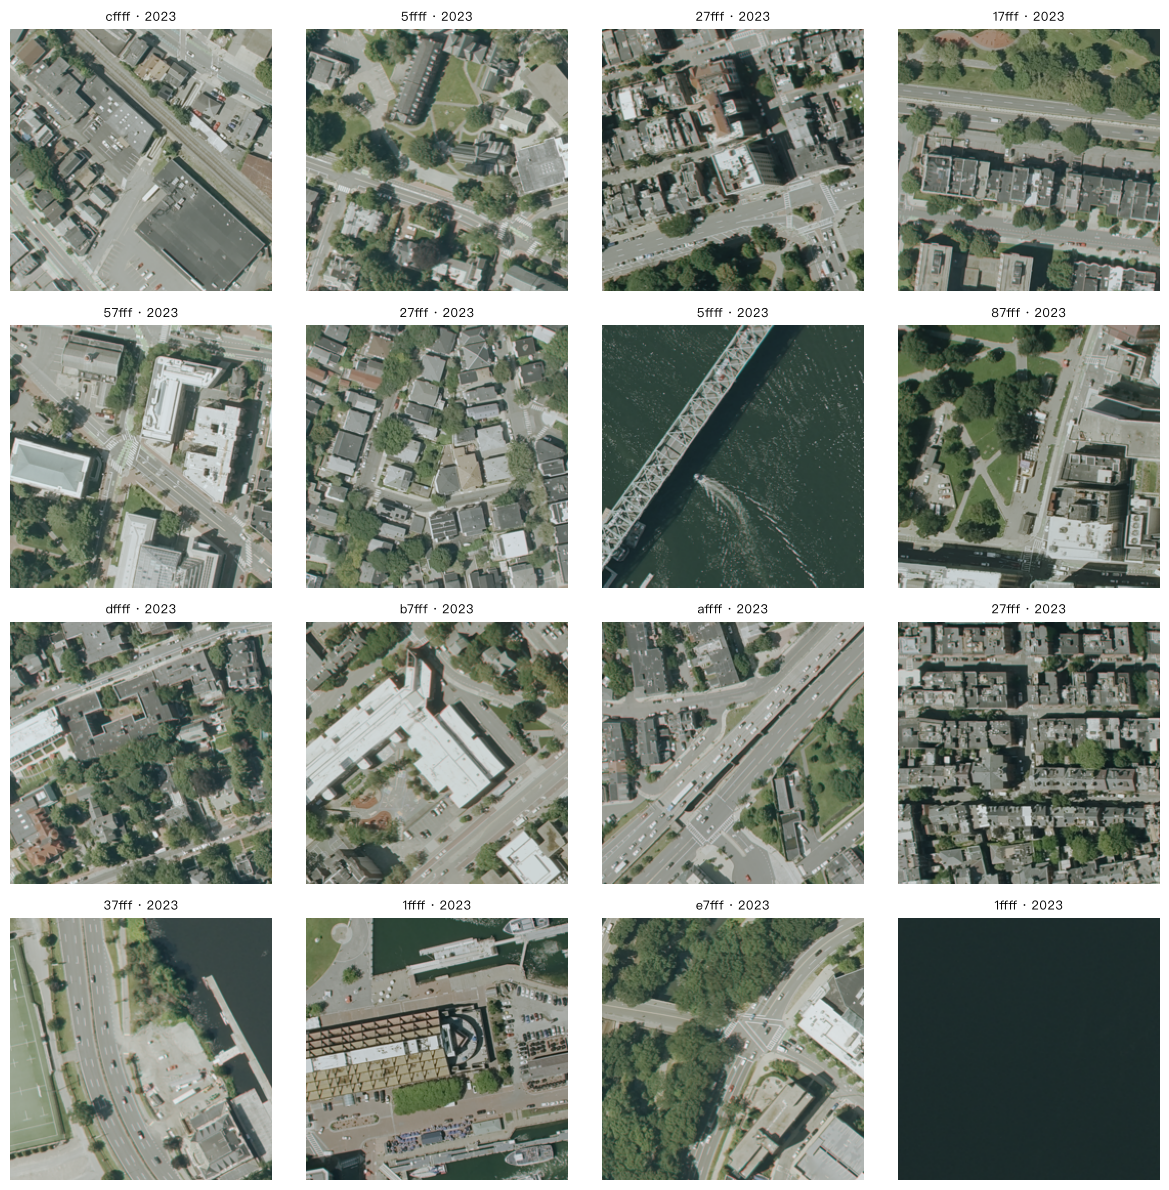

不可用 0 个


In [ ]:
import matplotlib.pyplot as plt

show = out[out.tile_ok].sample(n=min(16, int(out.tile_ok.sum())), random_state=SEED)
n = len(show); ncol = 4; nrow = max(int(np.ceil(n / ncol)), 1)
fig, axes = plt.subplots(nrow, ncol, figsize=(3 * ncol, 3 * nrow))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, r in zip(np.atleast_1d(axes).ravel(), show.itertuples()):
    with fs.open(path(r.tile_path), "rb") as f:
        ax.imshow(Image.open(f))
    ax.set_title(f"{r.cell_id[-5:]} · {int(r.naip_year)}", fontsize=9)
plt.tight_layout(); plt.show()

bad = out[~out.tile_ok]
print(f"不可用 {len(bad)} 个")
if len(bad):
    print(bad[["cell_id", "naip_item", "nodata_frac", "error"]].head(10).to_string(index=False))

## 8. 街景拍摄时间 vs 卫星图年份
街景和卫星图拍摄年份可能差好几年（新建了楼、砍了树），标签和输入就对不上。这里先看一眼差距分布，后面可以按差距过滤样本。

In [ ]:
gap = out.naip_year.astype("float") - pd.to_datetime(out.capture_max).dt.year
print("NAIP 年份 − 街景最新拍摄年份（正数 = 卫星图更新）：")
print(gap.value_counts().sort_index().to_string())

NAIP 年份 − 街景最新拍摄年份（正数 = 卫星图更新）：
-3.0     13
-2.0    374
-1.0    405
 0.0     25
 1.0     34
 2.0    195
 3.0     52
 4.0     28


## 9. 运行记录

In [ ]:
manifest = write_manifest({
    "step": "02_tiles", "city": str(cells.city.iloc[0]) if len(cells) else None,
    "tile_px": TILE_PX, "ground_m": GROUND_M, "naip_min_year": NAIP_MIN_YEAR,
    "input_cells": int(len(cells)), "tiles_ok": int(out.tile_ok.sum()),
    "naip_years": {str(int(k)): int(v) for k, v in out.naip_year.value_counts().items()},
    "outputs": ["processed/tiles", "processed/cells.parquet"],
    "finished_at": now_iso(),
}, "02_tiles_manifest.json")
print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "step": "02_tiles",
  "city": "boston",
  "tile_px": 256,
  "ground_m": 154,
  "naip_min_year": 2018,
  "input_cells": 1126,
  "tiles_ok": 1126,
  "naip_years": {
    "2023": 1126
  },
  "outputs": [
    "processed/tiles",
    "processed/cells.parquet"
  ],
  "finished_at": "2026-10-12T23:15:04Z"
}


## 下一步
- 下一个 notebook：`03_osm_features`，读取 `processed/cells.parquet`，为每个格子统计 OSM / WorldCover 特征。